In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
df=pd.read_csv('/content/drive/MyDrive/ted_recommendation_data.csv')

In [ ]:
print("Dataset shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nData types:")
print(df.dtypes)

Dataset shape: (4005, 8)

Columns:
['talk_id', 'title', 'speaker_1', 'description', 'topics', 'transcript', 'url', 'views']

Missing values:
talk_id        0
title          0
speaker_1      0
description    0
topics         0
transcript     0
url            0
views          0
dtype: int64

Data types:
talk_id         int64
title          object
speaker_1      object
description    object
topics         object
transcript     object
url            object
views           int64
dtype: object


In [ ]:
features = ["title", "topics", "description", "transcript"]
print(df[features].isnull().sum())

for col in features:
    df[col] = df[col].fillna("").astype(str)

df["content"] = (
    df["title"] + " " +
    df["topics"] + " " +
    df["description"] + " " +
    df["transcript"]
)

print("\nEmpty content rows:", df["content"].str.strip().eq("").sum())
print(df[["title", "content"]].head(3))

title          0
topics         0
description    0
transcript     0
dtype: int64

Empty content rows: 0
                             title  \
0      Averting the climate crisis   
1  The best stats you've ever seen   
2                 Simplicity sells   

                                             content  
0  Averting the climate crisis ['alternative ener...  
1  The best stats you've ever seen ['Africa', 'As...  
2  Simplicity sells ['computers', 'entertainment'...  


In [ ]:
import re
import ast
import pandas as pd

def clean_topics(value):
    if isinstance(value, list):
        topics_list = value
    else:
        try:
            parsed = ast.literal_eval(value)
            topics_list = parsed if isinstance(parsed, list) else [value]
        except (ValueError, SyntaxError):
            topics_list = [value]

    return " ".join(str(topic) for topic in topics_list)

def preprocess_text(text):
    text = str(text).lower()
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["topics_clean"] = df["topics"].apply(clean_topics)

df["content"] = (
    df["title"].fillna("") + " " +
    df["topics_clean"].fillna("") + " " +
    df["description"].fillna("") + " " +
    df["transcript"].fillna("")
)

df["content_clean"] = df["content"].apply(preprocess_text)

print(df[["title", "topics_clean", "content_clean"]].head(3))

                             title  \
0      Averting the climate crisis   
1  The best stats you've ever seen   
2                 Simplicity sells   

                                        topics_clean  \
0  alternative energy cars climate change culture...   
1  Africa Asia Google demo economics global issue...   
2  computers entertainment interface design media...   

                                       content_clean  
0  averting the climate crisis alternative energy...  
1  the best stats you ve ever seen africa asia go...  
2  simplicity sells computers entertainment inter...  


In [ ]:
import re
import ast
import pandas as pd

def clean_topics(value):
    if isinstance(value, list):
        topics_list = value
    else:
        try:
            parsed = ast.literal_eval(value)
            topics_list = parsed if isinstance(parsed, list) else [value]
        except (ValueError, SyntaxError):
            topics_list = [value]

    return " ".join(str(topic) for topic in topics_list)

def preprocess_text(text):
    text = str(text).lower()
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["topics_clean"] = df["topics"].apply(clean_topics)

df["content"] = (
    df["title"].fillna("") + " " +
    df["topics_clean"].fillna("") + " " +
    df["description"].fillna("") + " " +
    df["transcript"].fillna("")
)

# Apply preprocessing
df["content_clean"] = df["content"].apply(preprocess_text)

print(df[["title", "topics_clean", "content_clean"]].head(3))

                             title  \
0      Averting the climate crisis   
1  The best stats you've ever seen   
2                 Simplicity sells   

                                        topics_clean  \
0  alternative energy cars climate change culture...   
1  Africa Asia Google demo economics global issue...   
2  computers entertainment interface design media...   

                                       content_clean  
0  averting the climate crisis alternative energy...  
1  the best stats you ve ever seen africa asia go...  
2  simplicity sells computers entertainment inter...  


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True,
    dtype="float32"
)

tfidf_matrix = tfidf.fit_transform(df["content_clean"])

print("TF-IDF matrix shape:", tfidf_matrix.shape)
print("Vocabulary size:", len(tfidf.vocabulary_))
print("Matrix type:", type(tfidf_matrix))
print("Non-zero values:", tfidf_matrix.nnz)

/usr/local/lib/python3.13/dist-packages/sklearn/feature_extraction/text.py:2043: UserWarning: Only (<class 'numpy.float64'>, <class 'numpy.float32'>, <class 'numpy.float16'>) 'dtype' should be used. float32 'dtype' will be converted to np.float64.
  warnings.warn(


TF-IDF matrix shape: (4005, 10000)
Vocabulary size: 10000
Matrix type: <class 'scipy.sparse._csr.csr_matrix'>
Non-zero values: 1695263


In [ ]:
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity

df = df.reset_index(drop=True)

def recommend_talks(talk_title, top_n=5):
    matches = df.index[
        df["title"].str.casefold() == talk_title.casefold()
    ].tolist()

    if not matches:
        print("Talk not found. Please check the title.")
        return None

    talk_idx = matches[0]

    scores = cosine_similarity(
        tfidf_matrix[talk_idx],
        tfidf_matrix
    ).ravel()

    scores[talk_idx] = -1

    top_indices = np.argsort(scores)[::-1][:top_n]

    results = df.loc[
        top_indices, ["title", "speaker_1", "views", "url"]
    ].copy()

    results["similarity_score"] = scores[top_indices]

    return results.reset_index(drop=True)

In [ ]:
recommendations = recommend_talks(
    "Averting the climate crisis",
    top_n=5
)

display(recommendations)

,title,speaker_1,views,url,similarity_score
0,New thinking on the climate crisis,Al Gore,2187523,https://www.ted.com/talks/al_gore_new_thinking...,0.256182
1,How we can turn the tide on climate,Chris Anderson,1493370,https://www.ted.com/talks/christiana_figueres_...,0.244935
2,The case for optimism on climate change,Al Gore,2090031,https://www.ted.com/talks/al_gore_the_case_for...,0.236284
3,What comes after An Inconvenient Truth?,Al Gore,961451,https://www.ted.com/talks/al_gore_what_comes_a...,0.216815
4,Salvation (and profit) in greentech,John Doerr,1145381,https://www.ted.com/talks/john_doerr_salvation...,0.209224


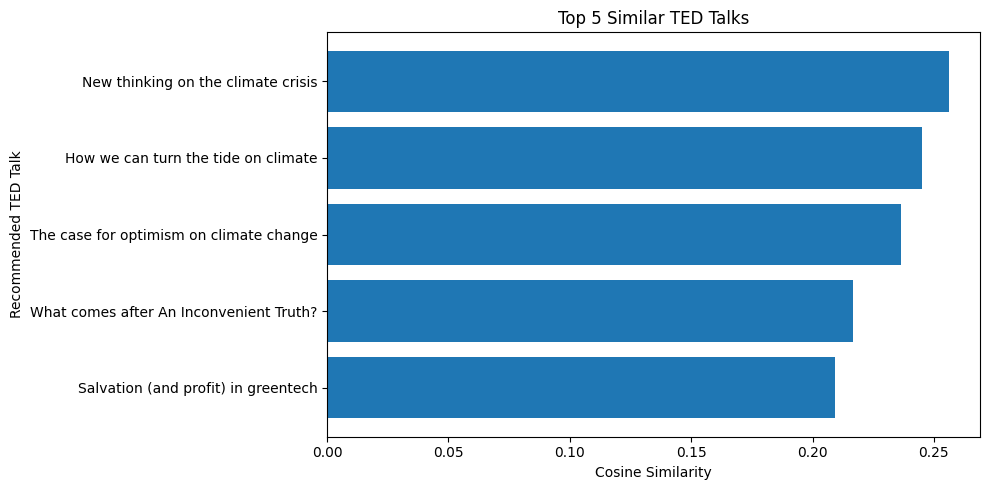

In [ ]:
import matplotlib.pyplot as plt

if recommendations is not None:
    plot_data = recommendations.sort_values(
        "similarity_score", ascending=True
    )

    plt.figure(figsize=(10, 5))
    plt.barh(
        plot_data["title"],
        plot_data["similarity_score"]
    )
    plt.xlabel("Cosine Similarity")
    plt.ylabel("Recommended TED Talk")
    plt.title("Top 5 Similar TED Talks")
    plt.tight_layout()
    plt.show()

In [ ]:
df[df["title"].str.contains(
    "AI|artificial intelligence|education",
    case=False,
    na=False
)][["title", "speaker_1"]].head(15)

,title,speaker_1
38,My wish: Manufactured landscapes and green edu...,Edward Burtynsky
60,In praise of slowness,Carl Honoré
69,Design is in the details,Paul Bennett
78,The route to a sustainable future,Alex Steffen
97,Technology's long tail,Chris Anderson
104,How brain science will change computing,Jeff Hawkins
119,Flip your thinking on AIDS in Africa,Emily Oster
126,Aid versus trade,Ngozi Okonjo-Iweala
135,Aid for Africa? No thanks.,Andrew Mwenda
150,3 clues to understanding your brain,Vilayanur Ramachandran


In [ ]:
ai_talks = df[
    df["content_clean"].str.contains(
        r"\bartificial intelligence\b|\bmachine learning\b|\bdeep learning\b|\bneural network\b|\bAI\b",
        case=False,
        na=False,
        regex=True
    )
]

display(ai_talks[["title", "speaker_1"]].drop_duplicates().head(20))

,title,speaker_1
17,"Organic design, inspired by nature",Ross Lovegrove
44,The accelerating power of technology,Ray Kurzweil
53,Is this our final century?,Martin Rees
83,What separates us from chimpanzees?,Jane Goodall
99,The genesis of Google,Sergey Brin
104,How brain science will change computing,Jeff Hawkins
147,"Building ""self-aware"" robots",Hod Lipson
180,TED's nonprofit transition,Chris Anderson
200,My wish: The Charter for Compassion,Karen Armstrong
247,Animate characters by evolving them,Torsten Reil


In [ ]:
ai_title = 'Building "self-aware" robots'

ai_recommendations = recommend_talks(ai_title, top_n=5)
display(ai_recommendations)

,title,speaker_1,views,url,similarity_score
0,Robots will invade our lives,Rodney Brooks,692492,https://www.ted.com/talks/rodney_brooks_robots...,0.190984
1,Tiny robots with giant potential,Paul McEuen,202353,https://www.ted.com/talks/paul_mceuen_and_marc...,0.189851
2,A robot that eats pollution,Jonathan Rossiter,1346330,https://www.ted.com/talks/jonathan_rossiter_a_...,0.188053
3,Robots inspired by cockroach ingenuity,Robert Full,1095105,https://www.ted.com/talks/robert_full_robots_i...,0.185666
4,Why we have an emotional connection to robots,Kate Darling,2529849,https://www.ted.com/talks/kate_darling_why_we_...,0.184667


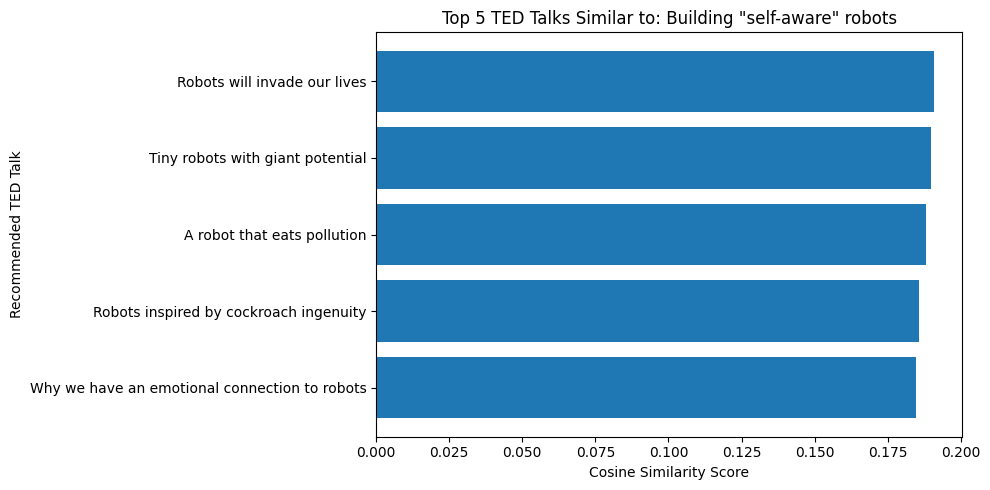

In [ ]:
import matplotlib.pyplot as plt

if ai_recommendations is not None:
    plot_data = ai_recommendations.sort_values(
        "similarity_score", ascending=True
    )

    plt.figure(figsize=(10, 5))
    plt.barh(
        plot_data["title"],
        plot_data["similarity_score"]
    )

    plt.xlabel("Cosine Similarity Score")
    plt.ylabel("Recommended TED Talk")
    plt.title(f"Top 5 TED Talks Similar to: {ai_title}")
    plt.tight_layout()

    plt.savefig(
        "ted_ai_recommendations.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

In [ ]:
import joblib
from scipy.sparse import save_npz

joblib.dump(tfidf, "ted_tfidf_vectorizer.joblib")
save_npz("ted_tfidf_matrix.npz", tfidf_matrix)

df[["talk_id", "title", "speaker_1", "url"]].to_csv(
    "ted_talk_metadata.csv", index=False
)

print("Saved vectorizer, TF-IDF matrix and metadata.")

Saved vectorizer, TF-IDF matrix and metadata.


In [ ]:
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

df["metadata_content"] = (
    df["title"].fillna("") + " " +
    df["topics_clean"].fillna("") + " " +
    df["description"].fillna("")
)
df["metadata_content_clean"] = df["metadata_content"].apply(preprocess_text)

tfidf_meta = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    min_df=1,
    sublinear_tf=True,
    dtype="float32"
)
tfidf_meta_matrix = tfidf_meta.fit_transform(df["metadata_content_clean"])

print("Metadata TF-IDF matrix shape:", tfidf_meta_matrix.shape)


/usr/local/lib/python3.13/dist-packages/sklearn/feature_extraction/text.py:2043: UserWarning: Only (<class 'numpy.float64'>, <class 'numpy.float32'>, <class 'numpy.float16'>) 'dtype' should be used. float32 'dtype' will be converted to np.float64.
  warnings.warn(


Metadata TF-IDF matrix shape: (4005, 153660)


In [ ]:
def recommend_talks_high_similarity(talk_title, top_n=5):
    matches = df.index[
        df["title"].str.casefold() == talk_title.casefold()
    ].tolist()

    if not matches:
        print("Talk not found. Please check the title.")
        return None

    talk_idx = matches[0]
    scores = cosine_similarity(
        tfidf_meta_matrix[talk_idx],
        tfidf_meta_matrix
    ).ravel()

    scores[talk_idx] = -1

    top_indices = np.argsort(scores)[::-1][:top_n]

    results = df.loc[
        top_indices, ["title", "speaker_1", "views", "url"]
    ].copy()

    results["similarity_score"] = scores[top_indices]
    return results.reset_index(drop=True)

high_sim_recs = recommend_talks_high_similarity('Building "self-aware" robots', top_n=5)
display(high_sim_recs)


,title,speaker_1,views,url,similarity_score
0,The rise of personal robots,Cynthia Breazeal,1208200,https://www.ted.com/talks/cynthia_breazeal_the...,0.108403
1,Robots inspired by cockroach ingenuity,Robert Full,1095105,https://www.ted.com/talks/robert_full_robots_i...,0.103180
2,"Robots that ""show emotion""",David Hanson,1109281,https://www.ted.com/talks/david_hanson_robots_...,0.088236
3,Increase your self-awareness with one simple fix,Tasha Eurich,2419723,https://www.ted.com/talks/tasha_eurich_increas...,0.083771
4,Robots will invade our lives,Rodney Brooks,692492,https://www.ted.com/talks/rodney_brooks_robots...,0.076998


In [ ]:
def recommend_talks_jaccard(talk_title, top_n=5):
    matches = df.index[
        df["title"].str.casefold() == talk_title.casefold()
    ].tolist()

    if not matches:
        print("Talk not found. Please check the title.")
        return None

    talk_idx = matches[0]
    target_topics = set(df.loc[talk_idx, "topics_clean"].split())

    scores = []
    for idx, row in df.iterrows():
        if idx == talk_idx:
            scores.append(-1.0)
            continue

        current_topics = set(row["topics_clean"].split())
        intersection = target_topics.intersection(current_topics)
        union = target_topics.union(current_topics)

        jaccard_score = len(intersection) / len(union) if len(union) > 0 else 0.0
        scores.append(jaccard_score)

    scores = np.array(scores)
    top_indices = np.argsort(scores)[::-1][:top_n]

    results = df.loc[
        top_indices, ["title", "speaker_1", "views", "url", "topics_clean"]
    ].copy()

    results["similarity_score"] = scores[top_indices]
    return results.reset_index(drop=True)

high_jaccard_recs = recommend_talks_jaccard('Building "self-aware" robots', top_n=5)
display(high_jaccard_recs)

,title,speaker_1,views,url,topics_clean,similarity_score
0,The sticky wonder of gecko feet,Robert Full,894701,https://www.ted.com/talks/robert_full_the_stic...,design evolution robots science technology,0.625000
1,Robots inspired by cockroach ingenuity,Robert Full,1095105,https://www.ted.com/talks/robert_full_robots_i...,animals design evolution robots science techno...,0.500000
2,"Meet Spot, the robot dog that can run, hop and...",Marc Raibert,4170986,https://www.ted.com/talks/marc_raibert_meet_sp...,robots future demo technology design,0.444444
3,Origami robots that reshape and transform them...,Jamie Paik,676822,https://www.ted.com/talks/jamie_paik_origami_r...,robots future design science demo space techno...,0.416667
4,Robots will invade our lives,Rodney Brooks,692492,https://www.ted.com/talks/rodney_brooks_robots...,AI design humanity intelligence robots technology,0.400000
